# Experiment 10: Markov Chain

## Aim
To construct a Markov Chain from observed state transitions, calculate its transition probability matrix, and predict future state probabilities.

## Dataset and source
- **Dataset:** Custom weather-state sequence created inside the program
- **States:** Sunny, Cloudy, Rainy
- **Number of observations:** 30
- **Kaggle download:** Not required
- **External data download:** Not required

This small sequence is used for demonstrating the algorithm clearly. For a real application, transition probabilities should be estimated from a larger representative dataset.

## Theory
A Markov Chain is a stochastic model describing transitions between states. It satisfies the **Markov property**: the probability of the next state depends only on the current state, not on the full sequence of previous states.

\[
P(X_{t+1}=j\mid X_t=i,X_{t-1},\ldots)=P(X_{t+1}=j\mid X_t=i)
\]

The transition probability from state \(i\) to state \(j\) is estimated as:

\[
P_{ij}=\frac{N_{ij}}{\sum_j N_{ij}}
\]

where \(N_{ij}\) is the observed number of transitions from state \(i\) to state \(j\). Each row of the transition matrix sums to 1 when that state has at least one observed outgoing transition.

For a row-vector state distribution \(\pi_t\), the distribution after one step is:

\[
\pi_{t+1}=\pi_t P
\]

After \(n\) steps:

\[
\pi_{t+n}=\pi_t P^n
\]

## Algorithm
1. Define a sequence of observed weather states.
2. Count transitions between consecutive states.
3. Normalize each row to calculate transition probabilities.
4. Set the initial state distribution.
5. Multiply the distribution by the transition matrix to predict future probabilities.
6. Display the transition matrix and multi-step probability plots.


## Program


Experiment: Markov Chain
Dataset source: Custom weather-state sequence
Number of observations: 30
States: ['Sunny', 'Cloudy', 'Rainy']

Transition Count Matrix:
        Sunny  Cloudy  Rainy
Sunny       3       5      1
Cloudy      6       2      5
Rainy       0       6      1

Transition Probability Matrix:
        Sunny  Cloudy  Rainy
Sunny   0.333   0.556  0.111
Cloudy  0.462   0.154  0.385
Rainy   0.000   0.857  0.143

Row sums (should be 1 for states with observed outgoing transitions):
Sunny     1.0
Cloudy    1.0
Rainy     1.0
dtype: float64

Starting state: Sunny
Predicted state probabilities after 1 step(s):
Sunny: 0.333
Cloudy: 0.556
Rainy: 0.111
Most likely next state: Cloudy

State probabilities from Sunny over the next 5 steps:
Step 1: Sunny=0.333, Cloudy=0.556, Rainy=0.111
Step 2: Sunny=0.368, Cloudy=0.366, Rainy=0.267
Step 3: Sunny=0.291, Cloudy=0.489, Rainy=0.220
Step 4: Sunny=0.323, Cloudy=0.425, Rainy=0.252
Step 5: Sunny=0.304, Cloudy=0.461, Rainy=0.235


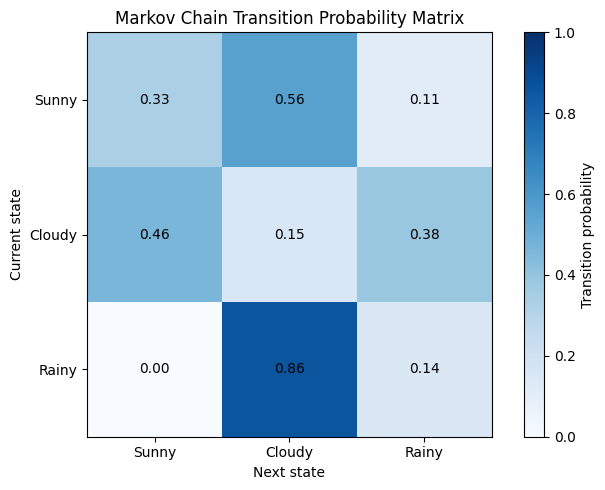

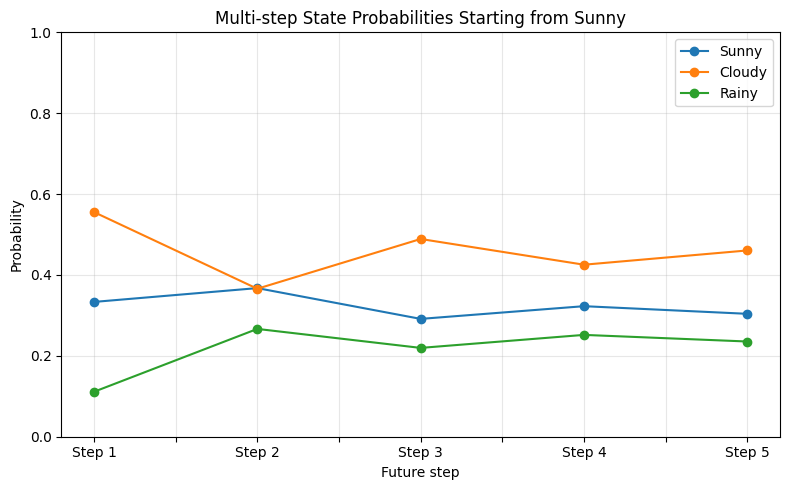


Markov property:
The next state is modeled using only the current state, not the full history of earlier states.


In [1]:
"""
Experiment 10: Markov Chain
Dataset: Custom state-transition sequence (created in this program)
Purpose: Estimate transition probabilities and predict future states.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define observed sequence of weather states.
# S = Sunny, C = Cloudy, R = Rainy
states = ["Sunny", "Cloudy", "Rainy"]
observed_sequence = [
    "Sunny", "Sunny", "Cloudy", "Rainy", "Cloudy",
    "Sunny", "Cloudy", "Cloudy", "Rainy", "Rainy",
    "Cloudy", "Sunny", "Sunny", "Cloudy", "Rainy",
    "Cloudy", "Sunny", "Cloudy", "Rainy", "Cloudy",
    "Sunny", "Sunny", "Cloudy", "Rainy", "Cloudy",
    "Cloudy", "Sunny", "Rainy", "Cloudy", "Sunny"
]

print("Experiment: Markov Chain")
print("Dataset source: Custom weather-state sequence")
print("Number of observations:", len(observed_sequence))
print("States:", states)

# 2. Count transitions between consecutive observations
transition_counts = pd.DataFrame(
    0, index=states, columns=states, dtype=int
)

for current_state, next_state in zip(
    observed_sequence[:-1], observed_sequence[1:]
):
    transition_counts.loc[current_state, next_state] += 1

print("\nTransition Count Matrix:")
print(transition_counts)

# 3. Convert transition counts to transition probabilities.
# Each row is normalized to sum to 1.
row_totals = transition_counts.sum(axis=1).replace(0, np.nan)
transition_matrix = transition_counts.div(row_totals, axis=0).fillna(0)

print("\nTransition Probability Matrix:")
print(transition_matrix.round(3))
print("\nRow sums (should be 1 for states with observed outgoing transitions):")
print(transition_matrix.sum(axis=1).round(3))

# 4. Predict the next state distribution from a starting state
starting_state = "Sunny"
steps = 1
initial_distribution = np.zeros(len(states))
initial_distribution[states.index(starting_state)] = 1.0

distribution = initial_distribution.copy()
for _ in range(steps):
    distribution = distribution @ transition_matrix.to_numpy()

print(f"\nStarting state: {starting_state}")
print(f"Predicted state probabilities after {steps} step(s):")
for state, probability in zip(states, distribution):
    print(f"{state}: {probability:.3f}")

most_likely_state = states[int(np.argmax(distribution))]
print("Most likely next state:", most_likely_state)

# 5. Predict distributions for multiple steps
print("\nState probabilities from Sunny over the next 5 steps:")
multi_step = initial_distribution.copy()
multi_step_results = []
for step in range(1, 6):
    multi_step = multi_step @ transition_matrix.to_numpy()
    multi_step_results.append(multi_step.copy())
    print(
        f"Step {step}: "
        + ", ".join(
            f"{state}={prob:.3f}"
            for state, prob in zip(states, multi_step)
        )
    )

# 6. Visualize transition probability matrix
plt.figure(figsize=(7, 5))
plt.imshow(transition_matrix.to_numpy(), cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Transition probability")
plt.xticks(range(len(states)), states)
plt.yticks(range(len(states)), states)
plt.xlabel("Next state")
plt.ylabel("Current state")
plt.title("Markov Chain Transition Probability Matrix")

for i in range(len(states)):
    for j in range(len(states)):
        plt.text(
            j, i, f"{transition_matrix.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

plt.tight_layout()
plt.show()

# 7. Visualize multi-step probabilities
results_df = pd.DataFrame(
    multi_step_results,
    index=[f"Step {i}" for i in range(1, 6)],
    columns=states
)
results_df.plot(kind="line", marker="o", figsize=(8, 5))
plt.ylabel("Probability")
plt.xlabel("Future step")
plt.title("Multi-step State Probabilities Starting from Sunny")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Demonstrate the Markov property
print("\nMarkov property:")
print(
    "The next state is modeled using only the current state, "
    "not the full history of earlier states."
)


## Expected output
The program prints the transition count matrix, transition probability matrix, row sums, next-state probabilities from Sunny, and probabilities for the next five steps. It displays a heatmap of transition probabilities and a line plot of multi-step state probabilities.

Because the sequence is custom and fixed in the program, the numerical results should be reproducible with NumPy and pandas.

## Result
A Markov Chain was constructed from the observed weather-state sequence. The transition probability matrix was calculated and used to estimate state probabilities over multiple future steps.

## Viva-voce questions and answers

**1. What is a Markov Chain?**  
A stochastic model that describes transitions between states using transition probabilities.

**2. What is the Markov property?**  
The next state depends only on the current state, rather than the entire past history.

**3. What is a state?**  
A possible condition or category the system can occupy, such as Sunny, Cloudy, or Rainy.

**4. What is a transition probability?**  
The probability of moving from one state to another in a single step.

**5. What is a transition matrix?**  
A matrix containing transition probabilities between every pair of states.

**6. Why should each row of the transition matrix sum to 1?**  
Each row represents all possible next states given the current state, and their probabilities must sum to 1.

**7. What is a stochastic process?**  
A collection of random variables indexed by time or another parameter, describing a system that evolves randomly.

**8. What is the difference between a Markov Chain and a Hidden Markov Model?**  
In a Markov Chain, states are directly observed. In a Hidden Markov Model, states are hidden and observations are generated probabilistically from those states.

**9. How do you predict the state distribution after multiple steps?**  
Multiply the current distribution by the transition matrix repeatedly, or use \(\pi_{t+n}=\pi_tP^n\).

**10. Where are Markov Chains used?**  
Weather modeling, queueing systems, web navigation, text generation, reliability analysis, and other systems with state transitions.

**11. What is a stationary distribution?**  
A probability distribution \(\pi\) satisfying \(\pi P=\pi\), so it remains unchanged after a transition.

**12. Is a Markov Chain a supervised learning algorithm?**  
Not necessarily. It is a probabilistic model; transition probabilities may be estimated from observed sequences without labelled input-output examples.
